In [94]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random

from pathlib import Path
from pyproj import Transformer

random.seed(42)

GRID_SIZE = 20
INTERVAL_MINUTES = 15

RAW_PATH = "../data/raw/CIBRS_Group_A_Public_Crime_Data_20261113.csv"
CENSUS_PATH = "../data/raw/2025_gaz_tracts_06.txt"
PROCESSED_DIR = Path("../data/processed")

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

In [127]:
NON_PATROL_OFFENSES = [
    "Counterfeiting/Forgery", 
    "Credit Card/Automatic Teller Fraud", 
    "Embezzlement", 
    "False Pretenses/Swindle/Confidence Game", 
    "Identity Theft", 
    "Impersonation", 
    "Hacking/Computer Invasion", 
    "Welfare Fraud", 
    "Betting/Wagering", 
    "Gambling Equipment Violations", 
    "Operating/Promoting/Assisting Gambling", 
    "Pornography/Obscene Material", 
    "Bribery"
]

In [128]:
ZIP_DICT = {
    "North": [92037, 92093, 92106, 92107, 92108, 92109, 
              92110, 92111, 92117, 92119, 92120, 92121, 
              92122, 92123, 92124, 92126, 92130, 92131, 
              92140, 92145, 92161,92007, 92008, 92009, 
              92010, 92011, 92014, 92024, 92054, 92055, 
              92056, 92057, 92058, 92067, 92075, 92081, 
              92083, 92084, 92091, 92672, 92003, 92004,
              92025, 92026, 92027, 92028, 92029, 92036, 
              92059, 92060, 92061, 92064, 92065, 92066, 
              92069, 92070, 92078, 92082, 92086, 92096, 
              92127, 92128, 92129, 92259, 92536], 
    "South": [91902, 91910, 91911, 91913, 91914, 91915, 
              91932, 91950, 92118, 92135, 92154, 92155, 92173], 
    "Central": [92101, 92102, 92103, 92104, 92105, 92113 , 
                92114, 92115, 92116, 92134, 92136, 92139, 92182], 
    "East": [91901, 91905, 91906, 91916, 91917, 91931, 91934, 
             91935, 91941, 91942, 91945, 91948, 91962, 91963, 
             91977, 91978, 91980, 92019, 92020, 92021, 92040, 92071]
}

## Loading raw dataset

In [130]:
crime_raw = pd.read_csv(RAW_PATH)

KEEP_COLUMNS = [
    "Incident UID",
    "Incident Date",
    "Zip Code",
    "Census Tract",
    "CIBRS Offense Description"
]

crime_clean = crime_raw[KEEP_COLUMNS].copy()
print("original # rows:", len(crime_raw))

print("columns:", crime_clean.columns.tolist())
display(crime_clean.head())

original # rows: 806935
columns: ['Incident UID', 'Incident Date', 'Zip Code', 'Census Tract', 'CIBRS Offense Description']


,Incident UID,Incident Date,Zip Code,Census Tract,CIBRS Offense Description
0,604311,2021 Jan 01 01:25:00 AM,92115.0,NaN,Destruction/Damage/Vandalism of Property
1,605986,2021 Jan 01 08:40:00 AM,92101.0,NaN,Impersonation
2,773968,2021 Jan 01 12:30:00 PM,NaN,NaN,Aggravated Assault
3,687369,2021 Jan 03 01:00:00 AM,92019.0,NaN,All Other Larceny
4,1072215,2021 Jan 03 04:37:00 PM,NaN,NaN,Simple Assault


## Cleaning cols/rows

In [131]:
#convert dats to datetime 
crime_clean["Incident Date"] = pd.to_datetime(
    crime_clean["Incident Date"],
    format="%Y %b %d %I:%M:%S %p",
    errors="coerce"
)

#remove invalid ids/ dates
crime_clean = crime_clean.dropna(
    subset=["Incident UID", "Incident Date"]
).copy()

crime_clean["Zip Code"] = pd.to_numeric(
    crime_clean["Zip Code"],
    errors="coerce"
).astype("Int64")

crime_clean["Census Tract"] = pd.to_numeric(
    crime_clean["Census Tract"],
    errors="coerce"
)

#remove rows without ZIP or census tract
crime_clean = crime_clean.dropna(
    subset=["Zip Code", "Census Tract"]
).copy()

print("cleaned zips, tract #rows :", len(crime_clean))
print("unique incidents:", crime_clean["Incident UID"].nunique())
print("unique zips:", crime_clean["Zip Code"].nunique())
print("unique tracts:", crime_clean["Census Tract"].nunique())

cleaned zips, tract #rows : 767880
unique incidents: 606150
unique zips: 112
unique tracts: 736


In [132]:
crime_clean = crime_clean[
    ~crime_clean["CIBRS Offense Description"].isin(
        NON_PATROL_OFFENSES
    )
].copy()

print("cleaned offenses #rows :", len(crime_clean))

print(
    "# offense types:",
    crime_clean["CIBRS Offense Description"].nunique()
)

cleaned offenses #rows : 721145
# offense types: 35


In [133]:
#time features 
crime_clean["Year"] = crime_clean["Incident Date"].dt.year
crime_clean["Month"] = crime_clean["Incident Date"].dt.month
crime_clean["Day"] = crime_clean["Incident Date"].dt.day
crime_clean["Hour"] = crime_clean["Incident Date"].dt.hour
crime_clean["Minute"] = crime_clean["Incident Date"].dt.minute

#divide into our intervals/steps 
crime_clean["Time Step"] = (
    crime_clean["Hour"] * 60
    + crime_clean["Minute"]
) // INTERVAL_MINUTES

display(crime_clean.head())

,Incident UID,Incident Date,Zip Code,Census Tract,CIBRS Offense Description,Year,Month,Day,Hour,Minute,Time Step
5,608584,2021-01-03 19:30:00,92110,68.02,Motor Vehicle Theft,2021,1,3,19,30,78
6,1002702,2021-01-03 20:00:00,92102,41.02,Motor Vehicle Theft,2021,1,3,20,0,80
10,642766,2021-01-05 16:00:00,91910,134.09,Motor Vehicle Theft,2021,1,5,16,0,64
11,548636,2021-01-06 22:39:00,92025,203.13,Motor Vehicle Theft,2021,1,6,22,39,90
14,1071423,2021-01-07 14:40:00,92110,66.00,Robbery,2021,1,7,14,40,58


## Geographic sampling
San Diego Boundaries: https://www.sandiegocounty.gov/content/sdc/bhs/county-zip-codes-regional-boundaries.html 

Since this is also sourced from SANDAG data from 2025, this should align enough with our crime dataset. 

1. North (North Central + North Inland + North Coastal) 
2. Central 
3. South 
4. East 

Roughly 10 random zip codes from each 

In [134]:
#select zips, stratified 
available_zips = set(
    crime_clean["Zip Code"].dropna().astype(int).unique()
)

selected_zips = {}

for region, region_zips in ZIP_DICT.items():

    valid_zips = [
        z for z in region_zips
        if z in available_zips
    ]

    if len(valid_zips) < 10:
        print(f"WARNING: {region} only has {len(valid_zips)} available ZIP codes.")

    selected_zips[region] = random.sample(
        valid_zips,
        min(10, len(valid_zips))
    )

print(selected_zips)

all_selected_zips = [
    zip_code
    for region_zips in selected_zips.values()
    for zip_code in region_zips
]

print("selected zip #:", len(all_selected_zips))

{'North': [92121, 92010, 92110, 92008, 92069, 92127, 92091, 92130, 92064, 92106], 'South': [92155, 91950, 92118, 91910, 91932, 92135, 91914, 91911, 92154, 91915], 'Central': [92134, 92104, 92102, 92101, 92139, 92105, 92182, 92136, 92114, 92116], 'East': [91941, 91977, 91948, 91931, 92021, 92019, 91934, 91945, 91917, 91980]}
selected zip #: 40


In [135]:
crime_sampled = crime_clean[
    crime_clean["Zip Code"].isin(all_selected_zips)
].copy()

print("row#:", len(crime_sampled))
print("unique zips:", crime_sampled["Zip Code"].nunique())
print("unique tracts:", crime_sampled["Census Tract"].nunique())

row#: 316563
unique zips: 40
unique tracts: 435


## Geospatial mapping

In [136]:
#get geoids to get lat/lon
def tract_to_geoid(value):

    if pd.isna(value):
        return pd.NA

    integer_part, decimal_part = f"{float(value):.2f}".split(".")

    tract_code = integer_part.zfill(4) + decimal_part

    return "06073" + tract_code


crime_sampled["GEOID"] = (
    crime_sampled["Census Tract"].apply(tract_to_geoid)
)

display(crime_sampled.head())

,Incident UID,Incident Date,Zip Code,Census Tract,CIBRS Offense Description,Year,Month,Day,Hour,Minute,Time Step,GEOID
5,608584,2021-01-03 19:30:00,92110,68.02,Motor Vehicle Theft,2021,1,3,19,30,78,06073006802
6,1002702,2021-01-03 20:00:00,92102,41.02,Motor Vehicle Theft,2021,1,3,20,0,80,06073004102
10,642766,2021-01-05 16:00:00,91910,134.09,Motor Vehicle Theft,2021,1,5,16,0,64,06073013409
14,1071423,2021-01-07 14:40:00,92110,66.00,Robbery,2021,1,7,14,40,58,06073006600
27,626466,2021-01-12 20:55:00,91911,129.00,Robbery,2021,1,12,20,55,83,06073012900


In [137]:
#load the census tract data to get coords 
census_raw = pd.read_csv(
    CENSUS_PATH,
    sep="|",
    dtype={"GEOID": str}
)

tract_coordinates = census_raw[
    census_raw["GEOID"].str.startswith("06073")
].copy()

tract_coordinates = tract_coordinates[
    ["GEOID", "INTPTLAT", "INTPTLONG"]
].copy()

tract_coordinates = tract_coordinates.rename(
    columns={
        "INTPTLAT": "lat",
        "INTPTLONG": "lon"
    }
)

selected_geoids = crime_sampled["GEOID"].dropna().unique()

tract_coordinates = tract_coordinates[
    tract_coordinates["GEOID"].isin(selected_geoids)
].copy()

print("geoids:", len(selected_geoids))
print("matched tracts:", tract_coordinates["GEOID"].nunique())

geoids: 435
matched tracts: 435


In [138]:
transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:32611",
    always_xy=True
)

tract_coordinates["x"], tract_coordinates["y"] = (
    transformer.transform(
        tract_coordinates["lon"].astype(float).values,
        tract_coordinates["lat"].astype(float).values
    )
)

tract_coordinates["grid_x"] = (
    (tract_coordinates["x"] - tract_coordinates["x"].min())
    / (tract_coordinates["x"].max() - tract_coordinates["x"].min())
    * GRID_SIZE
).astype(int).clip(0, GRID_SIZE - 1)

tract_coordinates["grid_y"] = (
    (tract_coordinates["y"].max() - tract_coordinates["y"])
    / (tract_coordinates["y"].max() - tract_coordinates["y"].min())
    * GRID_SIZE
).astype(int).clip(0, GRID_SIZE - 1)

print(
    "occupied grid cell #:",
    tract_coordinates[["grid_x", "grid_y"]].drop_duplicates().shape[0]
)

display(
    tract_coordinates[
        ["GEOID", "lat", "lon", "grid_x", "grid_y"]
    ].head()
)

occupied grid cell #: 97


,GEOID,lat,lon,grid_x,grid_y
6320,06073000100,32.752985,-117.185879,3,15
6322,06073000202,32.745395,-117.175154,3,15
6324,06073000302,32.744322,-117.159801,4,15
6326,06073000500,32.760514,-117.151950,4,14
6327,06073000600,32.752958,-117.151841,4,15


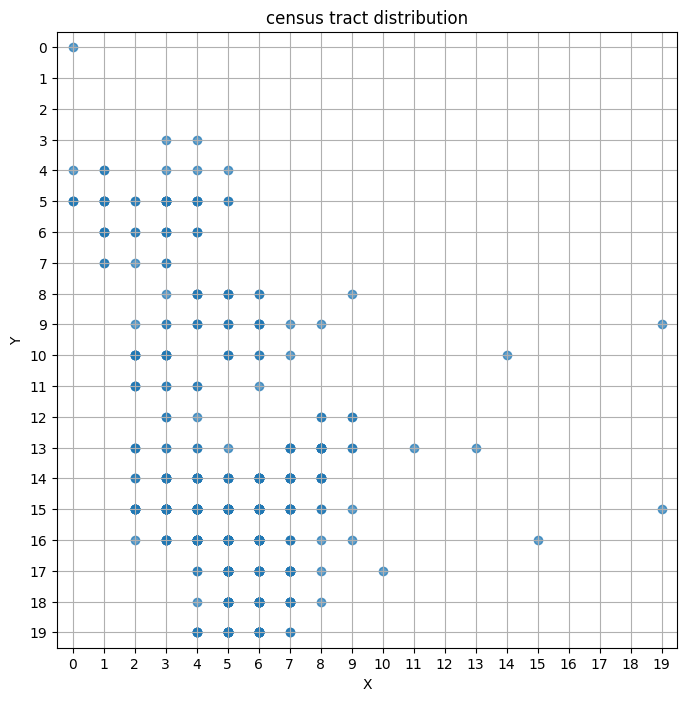

In [139]:
#checking distribution
plt.figure(figsize=(8, 8))

plt.scatter(
    tract_coordinates["grid_x"],
    tract_coordinates["grid_y"],
    alpha=0.7
)

plt.xlim(-0.5, GRID_SIZE - 0.5)
plt.ylim(GRID_SIZE - 0.5, -0.5)

plt.xticks(range(GRID_SIZE))
plt.yticks(range(GRID_SIZE))

plt.grid(True)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("census tract distribution")

plt.show()

In [140]:
crime_geocoded = crime_sampled.merge(
    tract_coordinates[["GEOID", "grid_x", "grid_y"]],
    on="GEOID",
    how="left",
    validate="many_to_one"
)

print("missing grid coords:", crime_geocoded["grid_x"].isna().sum())

display(crime_geocoded.head())

missing grid coords: 0


,Incident UID,Incident Date,Zip Code,Census Tract,CIBRS Offense Description,Year,Month,Day,Hour,Minute,Time Step,GEOID,grid_x,grid_y
0,608584,2021-01-03 19:30:00,92110,68.02,Motor Vehicle Theft,2021,1,3,19,30,78,06073006802,3,15
1,1002702,2021-01-03 20:00:00,92102,41.02,Motor Vehicle Theft,2021,1,3,20,0,80,06073004102,4,16
2,642766,2021-01-05 16:00:00,91910,134.09,Motor Vehicle Theft,2021,1,5,16,0,64,06073013409,6,17
3,1071423,2021-01-07 14:40:00,92110,66.00,Robbery,2021,1,7,14,40,58,06073006600,3,15
4,626466,2021-01-12 20:55:00,91911,129.00,Robbery,2021,1,12,20,55,83,06073012900,5,18


## Incident aggregation

In [ ]:
exact_duplicates = crime_geocoded.duplicated().sum()
print("exact dupes#:", exact_duplicates)
crime_geocoded = crime_geocoded.drop_duplicates().copy()
print("after deduping #:", len(crime_geocoded))

exact dupes#: 31418
after deduping #: 260563


In [141]:
uid_summary = (
    crime_geocoded.groupby("Incident UID")
    .agg(
        row_count=("Incident UID", "size"),
        distinct_offenses=("CIBRS Offense Description", "nunique"),
        offense_descriptions=(
            "CIBRS Offense Description",
            lambda x: list(x.dropna().unique())
        )
    )
    .reset_index()
)

repeated_uids = uid_summary[
    uid_summary["row_count"] > 1
]

print("unique incidents:", len(uid_summary))
print("incidents with multiple rows:", len(repeated_uids))

display(repeated_uids.head(20))

unique incidents: 246150
incidents with multiple rows: 60759


,Incident UID,row_count,distinct_offenses,offense_descriptions
5,414400,2,2,"[Theft From Building, Destruction/Damage/Vanda..."
21,414622,2,1,[Motor Vehicle Theft]
23,414810,2,1,[Motor Vehicle Theft]
24,414813,2,1,[Motor Vehicle Theft]
49,416111,2,2,"[Kidnaping/Abduction, Simple Assault]"
52,416156,2,1,[Motor Vehicle Theft]
53,416157,2,1,[Motor Vehicle Theft]
56,416252,2,1,[Motor Vehicle Theft]
57,416255,2,1,[Motor Vehicle Theft]
58,416963,2,1,[Motor Vehicle Theft]


In [142]:
CHECK_COLUMNS = [
    "Incident Date",
    "Zip Code",
    "Census Tract",
    "GEOID",
    "grid_x",
    "grid_y"
]

inconsistent_incidents = (
    crime_geocoded.groupby("Incident UID")[CHECK_COLUMNS]
    .nunique(dropna=False)
    .gt(1)
)

print("inconsistent values per column:")
print(inconsistent_incidents.sum())

print(
    "incidents with inconsistencies:",
    inconsistent_incidents.any(axis=1).sum()
)

inconsistent values per column:
Incident Date    0
Zip Code         0
Census Tract     0
GEOID            0
grid_x           0
grid_y           0
dtype: int64
incidents with inconsistencies: 0


In [143]:
crime_incidents = (
    crime_geocoded.groupby("Incident UID", as_index=False)
    .agg(
        {
            **{
                col: "first"
                for col in crime_geocoded.columns
                if col not in [
                    "Incident UID",
                    "CIBRS Offense Description"
                ]
            },

            "CIBRS Offense Description": (
                lambda x: " | ".join(
                    x.dropna().astype(str).unique()
                )
            )
        }
    )
)

crime_incidents["num_distinct_offenses"] = (
    crime_geocoded.groupby("Incident UID")[
        "CIBRS Offense Description"
    ].nunique().values
)

print("final row#:", len(crime_incidents))
print("dupe UIDs#:", crime_incidents["Incident UID"].duplicated().sum())

display(crime_incidents.head())

final row#: 246150
dupe UIDs#: 0


,Incident UID,Incident Date,Zip Code,Census Tract,Year,Month,Day,Hour,Minute,Time Step,GEOID,grid_x,grid_y,CIBRS Offense Description,num_distinct_offenses
0,414343,2021-01-02 02:00:00,91950,117.00,2021,1,2,2,0,8,06073011700,5,16,Destruction/Damage/Vandalism of Property,1
1,414344,2021-01-03 17:00:00,92110,91.07,2021,1,3,17,0,68,06073009107,3,14,Burglary/Breaking & Entering,1
2,414385,2021-01-08 10:57:00,92101,54.02,2021,1,8,10,57,43,06073005402,3,15,Simple Assault,1
3,414386,2021-01-02 11:48:00,92154,101.12,2021,1,2,11,48,47,06073010112,5,19,Weapon Law Violations,1
4,414391,2021-01-09 11:52:00,92130,83.69,2021,1,9,11,52,47,06073008369,2,10,Shoplifting,1


## Final crime incident data

In [144]:
output_path = PROCESSED_DIR / "crime_incidents.csv"

crime_incidents.to_csv(output_path, index=False)

print("saved:", output_path)

saved: ..\data\processed\crime_incidents.csv
